# TABLA CANCION

In [ ]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


In [ ]:
df = pd.read_json(DATA_RAW / "cancioninfo.json")
df


,blues.00000.wav,blues.00001.wav,blues.00002.wav,blues.00003.wav,blues.00004.wav,blues.00005.wav,blues.00006.wav,blues.00007.wav,blues.00008.wav,blues.00009.wav,...,rock.00090.wav,rock.00091.wav,rock.00092.wav,rock.00093.wav,rock.00094.wav,rock.00095.wav,rock.00096.wav,rock.00097.wav,rock.00098.wav,rock.00099.wav
t_id,blues.00000.wav,blues.00001.wav,blues.00002.wav,blues.00003.wav,blues.00004.wav,blues.00005.wav,blues.00006.wav,blues.00007.wav,blues.00008.wav,blues.00009.wav,...,rock.00090.wav,rock.00091.wav,rock.00092.wav,rock.00093.wav,rock.00094.wav,rock.00095.wav,rock.00096.wav,rock.00097.wav,rock.00098.wav,rock.00099.wav
duracion,138,142,96,111,191,231,160,186,None,243,...,156,202,181,160,89,101,170,121,99,144
genero,blues,blues,blues,blues,blues,blues,blues,blues,blues,blues,...,rock,rock,rock,rock,rock,rock,rock,rock,rock,rock
disco,blues4,blues7,blues5,blues10,blues1,blues13,blues13,blues7,blues7,blues13,...,rock14,rock19,rock5,rock3,rock2,rock19,rock13,rock0,rock3,rock4
autor,Stevie Ray Vaughan,Sonny Boy Williamson,Muddy Waters,Freddie King,Memphis Minnie,Magic Sam,Howlin' Wolf,Elmore James,Little Walter,Memphis Minnie,...,AC/DC,Eric Clapton,The Doors,Eric Clapton,The Rolling Stones,Pearl Jam,The Clash,Fleetwood Mac,Chuck Berry,Metallica


# Tratamiento de los datos JSON

In [ ]:
df_cancion = df.T.reset_index(drop=True)
df_cancion

,t_id,duracion,genero,disco,autor
0,blues.00000.wav,138,blues,blues4,Stevie Ray Vaughan
1,blues.00001.wav,142,blues,blues7,Sonny Boy Williamson
2,blues.00002.wav,96,blues,blues5,Muddy Waters
3,blues.00003.wav,111,blues,blues10,Freddie King
4,blues.00004.wav,191,blues,blues1,Memphis Minnie
...,...,...,...,...,...
995,rock.00095.wav,101,rock,rock19,Pearl Jam
996,rock.00096.wav,170,rock,rock13,The Clash
997,rock.00097.wav,121,rock,rock0,Fleetwood Mac
998,rock.00098.wav,99,rock,rock3,Chuck Berry


In [ ]:
#Renombramos las columnas
df_cancion.columns =['cancion', 'duracion', 'genero', 'disco', 'autor']
df_cancion

,cancion,duracion,genero,disco,autor
0,blues.00000.wav,138,blues,blues4,Stevie Ray Vaughan
1,blues.00001.wav,142,blues,blues7,Sonny Boy Williamson
2,blues.00002.wav,96,blues,blues5,Muddy Waters
3,blues.00003.wav,111,blues,blues10,Freddie King
4,blues.00004.wav,191,blues,blues1,Memphis Minnie
...,...,...,...,...,...
995,rock.00095.wav,101,rock,rock19,Pearl Jam
996,rock.00096.wav,170,rock,rock13,The Clash
997,rock.00097.wav,121,rock,rock0,Fleetwood Mac
998,rock.00098.wav,99,rock,rock3,Chuck Berry


# Primer analisis general de los datos



In [ ]:
#Comprobamos el tipo de dato y si exiten nulos
df_cancion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   cancion   1000 non-null   object
 1   duracion  982 non-null    object
 2   genero    1000 non-null   object
 3   disco     1000 non-null   object
 4   autor     1000 non-null   object
dtypes: object(5)
memory usage: 39.2+ KB


In [ ]:
df_cancion.head(5)

,cancion,duracion,genero,disco,autor
0,blues.00000.wav,138,blues,blues4,Stevie Ray Vaughan
1,blues.00001.wav,142,blues,blues7,Sonny Boy Williamson
2,blues.00002.wav,96,blues,blues5,Muddy Waters
3,blues.00003.wav,111,blues,blues10,Freddie King
4,blues.00004.wav,191,blues,blues1,Memphis Minnie


In [ ]:
df_cancion.tail(5)

,cancion,duracion,genero,disco,autor
995,rock.00095.wav,101,rock,rock19,Pearl Jam
996,rock.00096.wav,170,rock,rock13,The Clash
997,rock.00097.wav,121,rock,rock0,Fleetwood Mac
998,rock.00098.wav,99,rock,rock3,Chuck Berry
999,rock.00099.wav,144,rock,rock4,Metallica


In [ ]:
df_cancion.sample(5)

,cancion,duracion,genero,disco,autor
694,metal.00094.wav,142,metal,metal18,Cristina Scabbia
672,metal.00072.wav,None,metal,metal17,Randy Rhoads
987,rock.00087.wav,140,rock,rock5,Elton John
596,jazz.00096.wav,173,jazz,jazz2,Dizzy Gillespie
262,country.00062.wav,205,country,country12,Carrie Underwood


In [ ]:
#Buscamos duplicados en la columna canción
df_cancion['cancion'].duplicated().any()

np.False_

In [ ]:
#Como en la columna cancion hay 1000 valores únicos, para optimizar el espacio de la tabla se asignará un identificador para dicha columna.
#Añadimos la columna identificadora id_cancion
df_cancion['id_cancion'] = range(1, len(df_cancion)+1)
df_cancion

,cancion,duracion,genero,disco,autor,id_cancion
0,blues.00000.wav,138,blues,blues4,Stevie Ray Vaughan,1
1,blues.00001.wav,142,blues,blues7,Sonny Boy Williamson,2
2,blues.00002.wav,96,blues,blues5,Muddy Waters,3
3,blues.00003.wav,111,blues,blues10,Freddie King,4
4,blues.00004.wav,191,blues,blues1,Memphis Minnie,5
...,...,...,...,...,...,...
995,rock.00095.wav,101,rock,rock19,Pearl Jam,996
996,rock.00096.wav,170,rock,rock13,The Clash,997
997,rock.00097.wav,121,rock,rock0,Fleetwood Mac,998
998,rock.00098.wav,99,rock,rock3,Chuck Berry,999


In [ ]:
#Comprobamos si hay valores negativos en la columna duración
df_cancion[df_cancion['duracion'] < 0]

,cancion,duracion,genero,disco,autor,id_cancion


In [ ]:
#Vemos la cantidad de valores nulos que tenemos en la columna duración
nulos_duracion = df_cancion[df_cancion['duracion'].isna()]
print(f"La cantidad de nulos es: {len(df_cancion[df_cancion['duracion'].isna()])}")
print(f"El porcentaje de nulos es: {round(len(df_cancion[df_cancion['duracion'].isna()])/len(df_cancion)*100,1)}%")
display(nulos_duracion)

La cantidad de nulos es: 18
El porcentaje de nulos es: 1.8%


,cancion,duracion,genero,disco,autor,id_cancion
8,blues.00008.wav,None,blues,blues7,Little Walter,9
12,blues.00012.wav,None,blues,blues15,Bessie Smith,13
159,classical.00059.wav,None,classical,classical3,Dmitri Shostakovich,160
197,classical.00097.wav,None,classical,classical11,Aaron Copland,198
245,country.00045.wav,None,country,country2,Brad Paisley,246
254,country.00054.wav,None,country,country11,Loretta Lynn,255
284,country.00084.wav,None,country,country2,Loretta Lynn,285
366,disco.00066.wav,None,disco,disco9,Odyssey,367
468,hiphop.00068.wav,None,hiphop,hiphop4,Nicki Minaj,469
580,jazz.00080.wav,None,jazz,jazz9,Chet Baker,581


In [ ]:
#Transformamos la columna duración de segundos a un formato de tiempo HH:MM:SS ya que no tenemos valores negativos
df_cancion['duracion'] = pd.to_datetime(df_cancion['duracion'], unit='s', errors='coerce').dt.strftime('%H:%M:%S')
df_cancion.head(9)

,cancion,duracion,genero,disco,autor,id_cancion
0,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1
1,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2
2,blues.00002.wav,00:01:36,blues,blues5,Muddy Waters,3
3,blues.00003.wav,00:01:51,blues,blues10,Freddie King,4
4,blues.00004.wav,00:03:11,blues,blues1,Memphis Minnie,5
5,blues.00005.wav,00:03:51,blues,blues13,Magic Sam,6
6,blues.00006.wav,00:02:40,blues,blues13,Howlin' Wolf,7
7,blues.00007.wav,00:03:06,blues,blues7,Elmore James,8
8,blues.00008.wav,NaN,blues,blues7,Little Walter,9


In [ ]:
#Observamos si hay duplicados en la columna genero
df_cancion['genero'].duplicated().any()

np.True_

In [ ]:
#Veamos si nos merece la pena normalizar la columna género mediante la asignación de un identificador como hicimos con la columna canción
total_genero = df_cancion['genero'].nunique()
print(f"El número total de generos diferentes es: {total_genero}")
df_cancion['genero'].unique()

El número total de generos diferentes es: 10


array(['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz',
       'metal', 'pop', 'reggae', 'rock'], dtype=object)

In [ ]:
df_cancion['genero'].value_counts()

,count
genero,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100


In [ ]:
#Tenemos 10 generos diferentes que se repiten 100 veces cada uno
#Por lo tanto, para optimizar el almacenamiento construimos una tabla con un identificador único por genero
df_genero = df_cancion['genero'].drop_duplicates().reset_index(drop=True).to_frame()
df_genero['id_genero'] = range(1, len(df_genero)+1)
df_genero

,genero,id_genero
0,blues,1
1,classical,2
2,country,3
3,disco,4
4,hiphop,5
5,jazz,6
6,metal,7
7,pop,8
8,reggae,9
9,rock,10


In [ ]:
#Añadimos a la tabla canción la columna id_genero
df_cancion_con_idgenero = pd.merge(df_cancion, df_genero, on='genero', how='left')
df_cancion_con_idgenero

,cancion,duracion,genero,disco,autor,id_cancion,id_genero
0,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1
1,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2,1
2,blues.00002.wav,00:01:36,blues,blues5,Muddy Waters,3,1
3,blues.00003.wav,00:01:51,blues,blues10,Freddie King,4,1
4,blues.00004.wav,00:03:11,blues,blues1,Memphis Minnie,5,1
...,...,...,...,...,...,...,...
995,rock.00095.wav,00:01:41,rock,rock19,Pearl Jam,996,10
996,rock.00096.wav,00:02:50,rock,rock13,The Clash,997,10
997,rock.00097.wav,00:02:01,rock,rock0,Fleetwood Mac,998,10
998,rock.00098.wav,00:01:39,rock,rock3,Chuck Berry,999,10


In [ ]:
#Observamos si hay duplicados
df_cancion['disco'].duplicated().any()

np.True_

In [ ]:
#Vemos si nos merece la pena normalizar el campo disco mediante la asignación de un identificador
total_disco = df_cancion['disco'].nunique()
print(f"El número total de discos diferentes es: {total_disco}")
df_cancion['disco'].value_counts()

El número total de discos diferentes es: 200


,count
disco,
jazz3,14
country2,12
metal9,11
blues7,10
classical8,10
...,...
blues1,1
country4,1
country8,1


In [ ]:
#Tenemos 200 discos diferentes en un total de 1000 discos que tenemos con la tabla
#Por lo tanto, para optimizar el almacenamiento construimos una tabla con un identificador único por disco
df_discos = df_cancion['disco'].drop_duplicates().reset_index(drop=True).to_frame()
df_discos['id_disco'] = range(1, len(df_discos)+1)
df_discos

,disco,id_disco
0,blues4,1
1,blues7,2
2,blues5,3
3,blues10,4
4,blues1,5
...,...,...
195,rock9,196
196,rock19,197
197,rock7,198
198,rock1,199


In [ ]:
#Añadimos a la tabla canción el campo id_disco
df_cancion_con_iddisco = pd.merge(df_cancion_con_idgenero, df_discos, on='disco', how='left')
df_cancion_con_iddisco

,cancion,duracion,genero,disco,autor,id_cancion,id_genero,id_disco
0,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
1,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2,1,2
2,blues.00002.wav,00:01:36,blues,blues5,Muddy Waters,3,1,3
3,blues.00003.wav,00:01:51,blues,blues10,Freddie King,4,1,4
4,blues.00004.wav,00:03:11,blues,blues1,Memphis Minnie,5,1,5
...,...,...,...,...,...,...,...,...
995,rock.00095.wav,00:01:41,rock,rock19,Pearl Jam,996,10,197
996,rock.00096.wav,00:02:50,rock,rock13,The Clash,997,10,194
997,rock.00097.wav,00:02:01,rock,rock0,Fleetwood Mac,998,10,189
998,rock.00098.wav,00:01:39,rock,rock3,Chuck Berry,999,10,187


In [ ]:
#Observamos si hay duplicados en la columna autor
df_cancion['autor'].duplicated().any()

np.True_

In [ ]:
total_autor = df_cancion['autor'].nunique()
print(f"El número total de autores diferentes es: {total_autor}")
#df_cancion['autor'].unique()

El número total de autores diferentes es: 322


In [ ]:
# Importamos la tabla artista para obtener el identificador de cada autor
# (se genera en el notebook de artista_info como artistas_ids.csv).
_artistas_path = DATA_PROCESSED / "artistas_ids.csv"
if _artistas_path.exists():
    df_artistas = pd.read_csv(_artistas_path)
else:
    print("Aviso: aún no existe artistas_ids.csv. Ejecuta el notebook de artista_info y vuelve a correr esta celda.")
    df_artistas = pd.DataFrame(columns=["cancion", "artistas", "coste", "id_artista", "id_discografica"])
df_artistas


,cancion,artistas,discografica,coste,id_artista,id_discografica,genero
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01,1,1,blues
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85,2,2,blues
2,blues.00001.wav,Buddy Guy,Epic Records,4178.85,3,2,blues
3,blues.00002.wav,Muddy Waters,Merge Records,3226.40,4,3,blues
4,blues.00002.wav,Bessie Smith,Merge Records,3226.40,5,3,blues
...,...,...,...,...,...,...,...
1366,rock.00095.wav,Pearl Jam,Stax Records,3185.88,306,25,rock
1367,rock.00096.wav,The Clash,Sun Records,-503.65,321,1,rock
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297,9,rock
1369,rock.00098.wav,Chuck Berry,Motown,1425.79,301,20,rock


In [ ]:
#Unión de la tabla canción y la tabla artistas
df_cancion_1 = pd.merge(df_cancion_con_iddisco, df_artistas, left_on=['cancion','autor'], right_on=['cancion','artistas'], how='left')
df_cancion_1

,cancion,duracion,genero_x,disco,autor,id_cancion,id_genero,id_disco,artistas,discografica,coste,id_artista,id_discografica,genero_y
0,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1,Stevie Ray Vaughan,Sun Records,744.01,1,1,blues
1,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2,1,2,Sonny Boy Williamson,Epic Records,4178.85,2,2,blues
2,blues.00002.wav,00:01:36,blues,blues5,Muddy Waters,3,1,3,Muddy Waters,Merge Records,3226.40,4,3,blues
3,blues.00003.wav,00:01:51,blues,blues10,Freddie King,4,1,4,Freddie King,Republic Records,3618.77,6,4,blues
4,blues.00004.wav,00:03:11,blues,blues1,Memphis Minnie,5,1,5,Memphis Minnie,Jive Records,1990.81,7,5,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,rock.00095.wav,00:01:41,rock,rock19,Pearl Jam,996,10,197,Pearl Jam,Stax Records,3185.88,306,25,rock
996,rock.00096.wav,00:02:50,rock,rock13,The Clash,997,10,194,The Clash,Sun Records,-503.65,321,1,rock
997,rock.00097.wav,00:02:01,rock,rock0,Fleetwood Mac,998,10,189,Fleetwood Mac,XL Recordings,2170.05,297,9,rock
998,rock.00098.wav,00:01:39,rock,rock3,Chuck Berry,999,10,187,Chuck Berry,Motown,1425.79,301,20,rock


#Tabla para sql

Además, dado que la tabla cancion será la tabla principal en el procesamiento de datos en sql, vamos a introducir en la tabla canción los campos coste e id_discografica, que se encontraba en la tabla de artista adjuntada anteriormente

In [ ]:
#Contruimos la tabla final
df_cancion_final = df_cancion_1[['id_cancion','cancion', 'duracion', 'coste', 'id_genero', 'id_disco', 'id_artista','id_discografica']]
df_cancion_final.rename(columns={'id_artista':'id_autor'}, inplace=True)
df_cancion_final

/tmp/ipykernel_1289/1418436816.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cancion_final.rename(columns={'id_artista':'id_autor'}, inplace=True)


,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,1,blues.00000.wav,00:02:18,744.01,1,1,1,1
1,2,blues.00001.wav,00:02:22,4178.85,1,2,2,2
2,3,blues.00002.wav,00:01:36,3226.40,1,3,4,3
3,4,blues.00003.wav,00:01:51,3618.77,1,4,6,4
4,5,blues.00004.wav,00:03:11,1990.81,1,5,7,5
...,...,...,...,...,...,...,...,...
995,996,rock.00095.wav,00:01:41,3185.88,10,197,306,25
996,997,rock.00096.wav,00:02:50,-503.65,10,194,321,1
997,998,rock.00097.wav,00:02:01,2170.05,10,189,297,9
998,999,rock.00098.wav,00:01:39,1425.79,10,187,301,20


In [ ]:
df_cancion_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_cancion       1000 non-null   int64  
 1   cancion          1000 non-null   object 
 2   duracion         982 non-null    object 
 3   coste            1000 non-null   float64
 4   id_genero        1000 non-null   int64  
 5   id_disco         1000 non-null   int64  
 6   id_autor         1000 non-null   int64  
 7   id_discografica  1000 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 62.6+ KB


In [ ]:
# Extracción de la tabla para el procesamiento en sql
df_cancion_final.to_csv(DATA_PROCESSED / "cancion.csv", index=False)


In [ ]:
# Extracción de la tabla para el procesamiento en sql
df_discos.to_csv(DATA_PROCESSED / "id_disco.csv", index=False)


In [ ]:
# Extracción de la tabla para el procesamiento en sql
df_genero.to_csv(DATA_PROCESSED / "id_genero.csv", index=False)
df_cancion_con_iddisco.to_csv(DATA_PROCESSED / "cancion_ids.csv", index=False)


# Tratamiento de errores

In [ ]:
#Continuamos analizando la tabla original
df_cancion

,cancion,duracion,genero,disco,autor,id_cancion
0,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1
1,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2
2,blues.00002.wav,00:01:36,blues,blues5,Muddy Waters,3
3,blues.00003.wav,00:01:51,blues,blues10,Freddie King,4
4,blues.00004.wav,00:03:11,blues,blues1,Memphis Minnie,5
...,...,...,...,...,...,...
995,rock.00095.wav,00:01:41,rock,rock19,Pearl Jam,996
996,rock.00096.wav,00:02:50,rock,rock13,The Clash,997
997,rock.00097.wav,00:02:01,rock,rock0,Fleetwood Mac,998
998,rock.00098.wav,00:01:39,rock,rock3,Chuck Berry,999


En el primer analisis de los datos unicamente hemos observado la presencia de datos incorrectos en la columna duración. Dado que disponemos de los archivos de audio de las canciones en los datos del proyecto, proponemos que la limpieza para esta tabla sea obtener la duración de aquellas canciones que presentan valores faltantes a partir de dichos archivos.

#Limpieza de datos

In [ ]:
# Se añade la duración de las canciones mediante los archivos de audio (si están en Data/raw)
import librosa

lista_canciones_sin_duracion = list(nulos_duracion['cancion'])
print(lista_canciones_sin_duracion)

i = 0
while i < len(lista_canciones_sin_duracion):
    ruta = DATA_RAW / lista_canciones_sin_duracion[i]
    if ruta.exists():
        audio, sr = librosa.load(str(ruta), sr=None)
        duracion_cancion = librosa.get_duration(y=audio, sr=sr)
        duracion_cancion_time = pd.to_timedelta(duracion_cancion, unit='s').round('1s')
        duracion_cancion_time1 = str(duracion_cancion_time).split(' ')[-1]
        df_cancion.loc[df_cancion['cancion'] == lista_canciones_sin_duracion[i], 'duracion'] = duracion_cancion_time1
    else:
        print(f"Audio no encontrado (se omite): {ruta}")
    i += 1

i = 0
while i < len(lista_canciones_sin_duracion):
    display(df_cancion[df_cancion['cancion'] == lista_canciones_sin_duracion[i]])
    i += 1


['blues.00008.wav', 'blues.00012.wav', 'classical.00059.wav', 'classical.00097.wav', 'country.00045.wav', 'country.00054.wav', 'country.00084.wav', 'disco.00066.wav', 'hiphop.00068.wav', 'jazz.00080.wav', 'metal.00072.wav', 'pop.00012.wav', 'pop.00076.wav', 'pop.00078.wav', 'rock.00005.wav', 'rock.00045.wav', 'rock.00053.wav', 'rock.00078.wav']


,cancion,duracion,genero,disco,autor,id_cancion
8,blues.00008.wav,00:00:30,blues,blues7,Little Walter,9


,cancion,duracion,genero,disco,autor,id_cancion
12,blues.00012.wav,00:00:30,blues,blues15,Bessie Smith,13


,cancion,duracion,genero,disco,autor,id_cancion
159,classical.00059.wav,00:00:30,classical,classical3,Dmitri Shostakovich,160


,cancion,duracion,genero,disco,autor,id_cancion
197,classical.00097.wav,00:00:30,classical,classical11,Aaron Copland,198


,cancion,duracion,genero,disco,autor,id_cancion
245,country.00045.wav,00:00:30,country,country2,Brad Paisley,246


... (9 outputs left out)

,cancion,duracion,genero,disco,autor,id_cancion
905,rock.00005.wav,00:00:30,rock,rock12,David Bowie,906


,cancion,duracion,genero,disco,autor,id_cancion
945,rock.00045.wav,00:00:30,rock,rock19,The Clash,946


,cancion,duracion,genero,disco,autor,id_cancion
953,rock.00053.wav,00:00:30,rock,rock2,The Who,954


,cancion,duracion,genero,disco,autor,id_cancion
978,rock.00078.wav,00:00:30,rock,rock10,Led Zeppelin,979


In [ ]:
#Comprobamos que no hay nulos
df_cancion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   cancion     1000 non-null   object
 1   duracion    1000 non-null   object
 2   genero      1000 non-null   object
 3   disco       1000 non-null   object
 4   autor       1000 non-null   object
 5   id_cancion  1000 non-null   int64 
dtypes: int64(1), object(5)
memory usage: 47.0+ KB


#Regla de negocio

Regla de negocio: Una canción no puede durar más de 13 minutos.

In [ ]:
#Vemos las canciones que no cumplen dicha regla
canciones_incumple_regla = df_cancion[df_cancion['duracion'] > '00:13:00']
print(f"Hay {len(canciones_incumple_regla)} canciones que no cumple la regla de negocio")
print(f"El {len(canciones_incumple_regla)/len(df_cancion)*100}% de canciones no cumplen la regla de negocio")
display(canciones_incumple_regla)

Hay 24 canciones que no cumple la regla de negocio
El 2.4% de canciones no cumplen la regla de negocio


,cancion,duracion,genero,disco,autor,id_cancion
35,blues.00035.wav,00:13:31,blues,blues14,Koko Taylor,36
120,classical.00020.wav,00:13:37,classical,classical10,Modest Mussorgsky,121
184,classical.00084.wav,00:13:23,classical,classical8,Edward Elgar,185
234,country.00034.wav,00:13:23,country,country7,Kris Kristofferson,235
246,country.00046.wav,00:13:32,country,country0,Shania Twain,247
417,hiphop.00017.wav,00:13:05,hiphop,hiphop3,J. Cole,418
456,hiphop.00056.wav,00:13:33,hiphop,hiphop14,Rakim,457
577,jazz.00077.wav,00:13:33,jazz,jazz0,John Coltrane,578
591,jazz.00091.wav,00:13:31,jazz,jazz19,Billie Holiday,592
610,metal.00010.wav,00:13:16,metal,metal16,Floor Jansen,611


In [ ]:
#Cantidad de canciones que no cumple la regla de negocio por genero
canciones_incumple_regla['genero'].value_counts().reset_index(name='cantidad')

,genero,cantidad
0,metal,5
1,pop,4
2,rock,3
3,reggae,3
4,jazz,2
5,country,2
6,hiphop,2
7,classical,2
8,blues,1


In [ ]:
#Porcentaje de canciones con una duración superior a 13 minutos sobre el total de canciones de cada género
total_genero = df_cancion['genero'].value_counts()
incumplen_genero = canciones_incumple_regla['genero'].value_counts()

porcentaje = ((incumplen_genero/total_genero*100).round(2).reset_index())
porcentaje.columns = ['genero', 'porcentaje']
porcentaje

,genero,porcentaje
0,blues,1.0
1,classical,2.0
2,country,2.0
3,disco,NaN
4,hiphop,2.0
5,jazz,2.0
6,metal,5.0
7,pop,4.0
8,reggae,3.0
9,rock,3.0


La regla de negocio presenta un alto nivel de cumplimiento en el conjunto de datos. El análisis por género muestra que el porcentaje de canciones con una duración superior a 13 minutos es reducido en todas las categorías, situándose entre el 1 % y el 5 % del total de canciones de cada género. Aunque metal y pop registran los valores más elevados, estos siguen siendo bajos, lo que indica que la eliminación por el incumplimiento de la regla no constituye un problema relevante ni se concentra de forma significativa en ningún género específico.

In [ ]:
canciones_incumple_regla['disco'].value_counts().reset_index(name='cantidad')

,disco,cantidad
0,blues14,1
1,classical10,1
2,classical8,1
3,country7,1
4,country0,1
5,hiphop3,1
6,hiphop14,1
7,jazz0,1
8,jazz19,1
9,metal16,1


In [ ]:
#Porcentaje de canciones con una duración superior a 13 minutos sobre el total de canciones de cada disco
total_disco = df_cancion['disco'].value_counts()
incumplen_disco = canciones_incumple_regla['disco'].value_counts()

porcentaje = ((incumplen_disco/total_disco*100).round(2).reset_index())
porcentaje.columns = ['disco', 'porcentaje']
porcentaje[porcentaje['porcentaje'].notna()]

,disco,porcentaje
6,blues14,20.00
22,classical10,25.00
38,classical8,10.00
40,country0,25.00
57,country7,25.00
86,hiphop14,25.00
93,hiphop3,33.33
100,jazz0,20.00
111,jazz19,25.00
121,metal1,16.67


In [ ]:
canciones_incumple_regla['autor'].value_counts().reset_index(name='cantidad')

,autor,cantidad
0,SOJA,2
1,Alissa White-Gluz,2
2,Edward Elgar,1
3,Kris Kristofferson,1
4,Koko Taylor,1
5,Modest Mussorgsky,1
6,J. Cole,1
7,Shania Twain,1
8,Billie Holiday,1
9,Rakim,1


In [ ]:
#Porcentaje de canciones con una duración superior a 13 minutos sobre el total de canciones de cada disco
total_autor = df_cancion['autor'].value_counts()
incumplen_autor = canciones_incumple_regla['autor'].value_counts()

porcentaje = ((incumplen_autor/total_autor*100).round(2).reset_index())
porcentaje.columns = ['autor', 'porcentaje']
porcentaje[porcentaje['porcentaje'].notna()]

,autor,porcentaje
13,Alissa White-Gluz,50.00
15,Angela Gossow,50.00
19,Ariana Grande,25.00
34,Billie Eilish,20.00
35,Billie Holiday,33.33
68,Chronixx,25.00
69,Chuck Berry,14.29
90,Doro Pesch,100.00
96,Edward Elgar,33.33
108,Floor Jansen,14.29


Sin embargo, el impacto de eliminar las canciones con una duración superior a 13 minutos no es homogéneo entre los distintos discos y autores. A nivel de disco, existen casos en los que la eliminación de estas canciones supondría una reducción significativa, por ejemplo, en el disco rock7 se perdería el 50 % de las canciones. De forma similar, a nivel de autor, algunos artistas verían reducido su catálogo en un 50 % e incluso, en determinados casos, la eliminación afectaría al 100 % de sus canciones. Esto indica que, aunque el incumplimiento de la regla es reducido en términos generales, su impacto puede ser considerable para determinados discos o autores con un número limitado de canciones.

# EDA

In [ ]:
#Analizamos la variable numérica
#La columna duración se paso a tiempo para facitiar los calculos en sql, pero para realizar el EDA necesitamos que la columna duración vuelva a estar en segundos

In [ ]:
df_cancion['duracion'] = pd.to_timedelta(df_cancion['duracion']).dt.total_seconds()
df_cancion

,cancion,duracion,genero,disco,autor,id_cancion
0,blues.00000.wav,138.0,blues,blues4,Stevie Ray Vaughan,1
1,blues.00001.wav,142.0,blues,blues7,Sonny Boy Williamson,2
2,blues.00002.wav,96.0,blues,blues5,Muddy Waters,3
3,blues.00003.wav,111.0,blues,blues10,Freddie King,4
4,blues.00004.wav,191.0,blues,blues1,Memphis Minnie,5
...,...,...,...,...,...,...
995,rock.00095.wav,101.0,rock,rock19,Pearl Jam,996
996,rock.00096.wav,170.0,rock,rock13,The Clash,997
997,rock.00097.wav,121.0,rock,rock0,Fleetwood Mac,998
998,rock.00098.wav,99.0,rock,rock3,Chuck Berry,999


In [ ]:
#Sacar estadísticos
df_cancion['duracion'].describe()

,duracion
count,1000.000000
mean,153.621000
std,113.028921
min,0.000000
25%,108.000000
50%,142.000000
75%,173.000000
max,817.000000


In [ ]:
df_cancion['duracion'].median()

142.0

La media es superior a la mediana, lo que indica presencia de valores extremos.

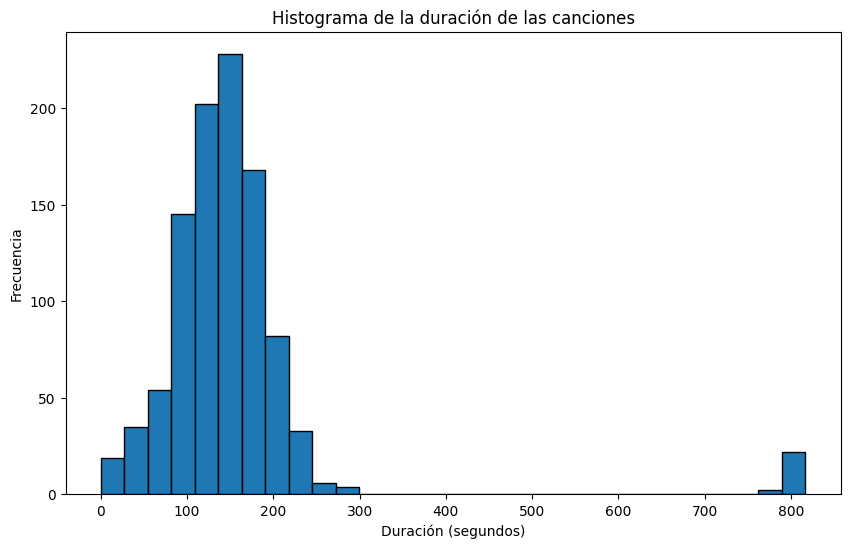

In [ ]:
#Histograma
plt.figure(figsize=(10, 6))
plt.hist(df_cancion['duracion'], bins=30, edgecolor='black')
plt.xlabel('Duración (segundos)')
plt.ylabel('Frecuencia')
plt.title('Histograma de la duración de las canciones')
plt.show()

La mayoria de las canciones tiene una duración entre 100 y 200 segundos pero se observa un pequeño grupo de canciones con duración extremadamente alta, alejadas del resto.

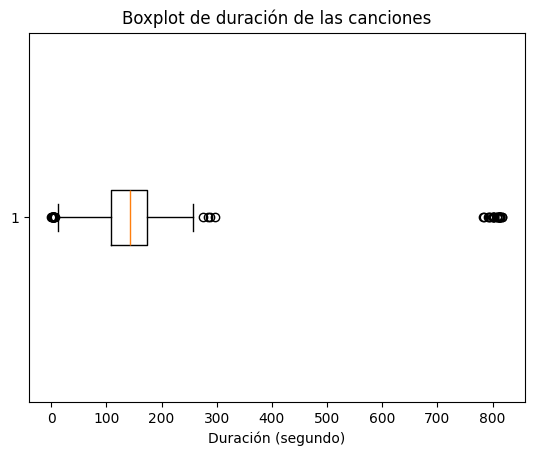

In [ ]:
#Veamos los outliers
plt.figure()
plt.boxplot(df_cancion['duracion'], vert=False)
plt.xlabel('Duración (segundo)')
plt.title('Boxplot de duración de las canciones')
plt.show()


In [ ]:
Q1 = df_cancion['duracion'].quantile(0.25)
Q3 = df_cancion['duracion'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Límite inferior: {lower_bound:.2f}")
print(f"Límite superior: {upper_bound:.2f}")

outliers = df_cancion[(df_cancion['duracion']< lower_bound) | (df_cancion['duracion'] > upper_bound)]
print(f"Cantidad de outliers: {len(outliers)}")
print(f"Porcentaje de outliers: {round(len(outliers)/len(df_cancion['duracion'])*100,2)}%")

Q1: 108.00
Q3: 173.00
IQR: 65.00
Límite inferior: 10.50
Límite superior: 270.50
Cantidad de outliers: 43
Porcentaje de outliers: 4.3%


In [ ]:
outliers[['cancion', 'duracion']].sort_values('duracion').head(5)

,cancion,duracion
499,hiphop.00099.wav,0.0
955,rock.00055.wav,1.0
653,metal.00053.wav,2.0
393,disco.00093.wav,2.0
750,pop.00050.wav,2.0


In [ ]:
outliers[['cancion', 'duracion']].sort_values('duracion').tail(5)

,cancion,duracion
911,rock.00011.wav,813.0
577,jazz.00077.wav,813.0
645,metal.00045.wav,814.0
120,classical.00020.wav,817.0
714,pop.00014.wav,817.0


In [ ]:
#Quitamos de df_cancion los outliers
df_cancion_sin_outliers = df_cancion[(df_cancion['duracion']> lower_bound) & (df_cancion['duracion'] < upper_bound)]
df_cancion_sin_outliers

,cancion,duracion,genero,disco,autor,id_cancion
0,blues.00000.wav,138.0,blues,blues4,Stevie Ray Vaughan,1
1,blues.00001.wav,142.0,blues,blues7,Sonny Boy Williamson,2
2,blues.00002.wav,96.0,blues,blues5,Muddy Waters,3
3,blues.00003.wav,111.0,blues,blues10,Freddie King,4
4,blues.00004.wav,191.0,blues,blues1,Memphis Minnie,5
...,...,...,...,...,...,...
995,rock.00095.wav,101.0,rock,rock19,Pearl Jam,996
996,rock.00096.wav,170.0,rock,rock13,The Clash,997
997,rock.00097.wav,121.0,rock,rock0,Fleetwood Mac,998
998,rock.00098.wav,99.0,rock,rock3,Chuck Berry,999


In [ ]:
print('Con outliers')
print(df_cancion['duracion'].describe())
print('\nSin outliers')
print(df_cancion_sin_outliers['duracion'].describe())

Con outliers
count    1000.000000
mean      153.621000
std       113.028921
min         0.000000
25%       108.000000
50%       142.000000
75%       173.000000
max       817.000000
Name: duracion, dtype: float64

Sin outliers
count    957.000000
mean     139.082550
std       45.359679
min       12.000000
25%      109.000000
50%      141.000000
75%      170.000000
max      257.000000
Name: duracion, dtype: float64


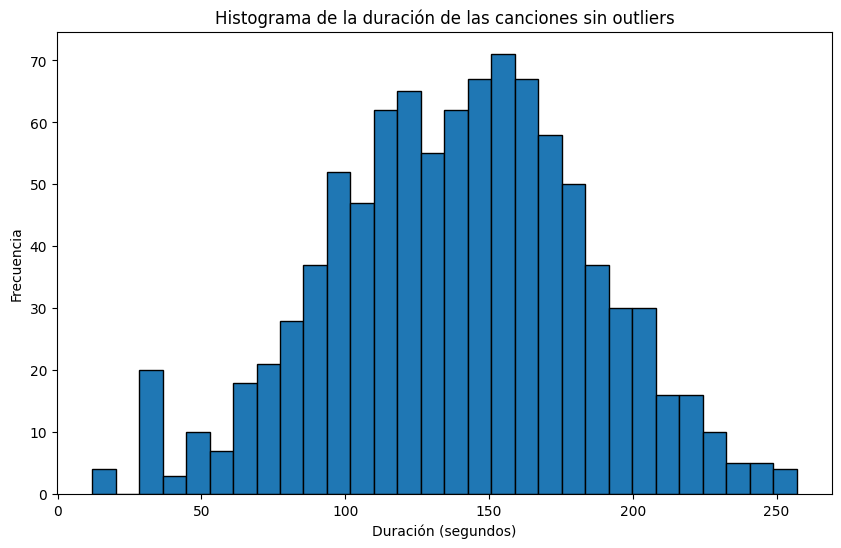

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df_cancion_sin_outliers['duracion'], bins=30, edgecolor='black')
plt.xlabel('Duración (segundos)')
plt.ylabel('Frecuencia')
plt.title('Histograma de la duración de las canciones sin outliers')
plt.show()

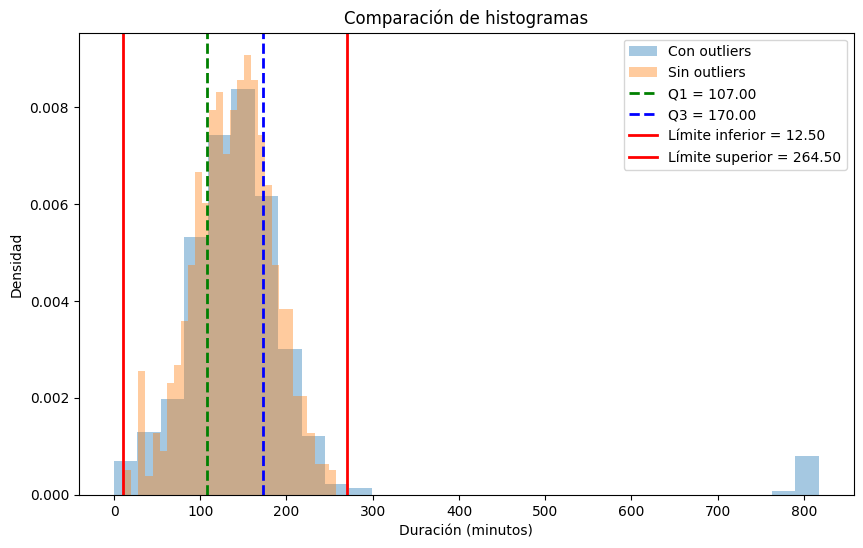

In [ ]:
plt.figure(figsize=(10,6))

plt.hist(df_cancion['duracion'], bins=30, density=True, alpha=0.4, label='Con outliers')
plt.hist(df_cancion_sin_outliers['duracion'], bins=30, density=True, alpha=0.4, label='Sin outliers')
# Líneas verticales
plt.axvline(Q1, color='green', linestyle='--', linewidth=2, label='Q1 = 107.00')
plt.axvline(Q3, color='blue', linestyle='--', linewidth=2, label='Q3 = 170.00')

plt.axvline(lower_bound, color='red', linestyle='-', linewidth=2, label='Límite inferior = 12.50')
plt.axvline(upper_bound, color='red', linestyle='-', linewidth=2, label='Límite superior = 264.50')


plt.xlabel('Duración (minutos)')
plt.ylabel('Densidad')
plt.title('Comparación de histogramas')
plt.legend()
plt.show()


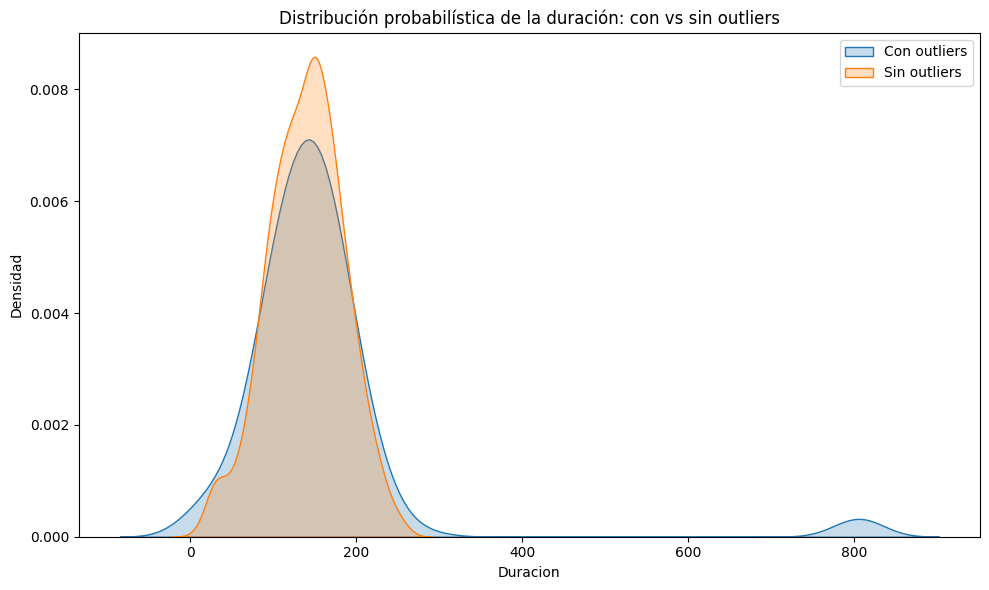

In [ ]:
#hacemos una compración tambien de la distribución probabilistica
plt.figure(figsize=(10,6))

# Distribución con outliers
sns.kdeplot(
    data=df_cancion,
    x="duracion",
    fill=True,
    label="Con outliers"
)

# Distribución sin outliers
sns.kdeplot(
    data=df_cancion_sin_outliers,
    x="duracion",
    fill=True,
    label="Sin outliers"
)

plt.title("Distribución probabilística de la duración: con vs sin outliers")
plt.xlabel("Duracion")
plt.ylabel("Densidad")
plt.legend()

plt.tight_layout()
plt.show()

Al comparar la distribución de la duración con y sin valores atípicos, se observa que los outliers generan una cola hacia la derecha que distorsiona la distribución. Sin embargo, al eliminarlos, la forma principal de la distribución se mantiene prácticamente igual, representando de forma más fiel el comportamiento de la mayoría de las observaciones. Por este motivo, se decide trabajar con el conjunto de datos sin outliers en los análisis posteriores.

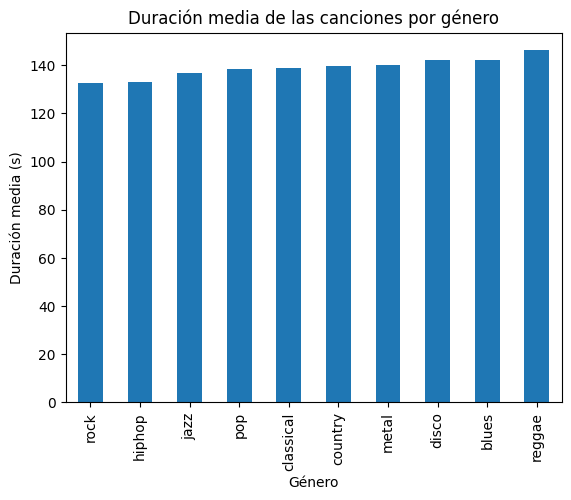

In [ ]:
df_cancion_sin_outliers.groupby('genero')["duracion"].mean().sort_values().plot(kind='bar')
plt.title('Duración media de las canciones por género')
plt.xlabel("Género")
plt.ylabel("Duración media (s)")
plt.show()

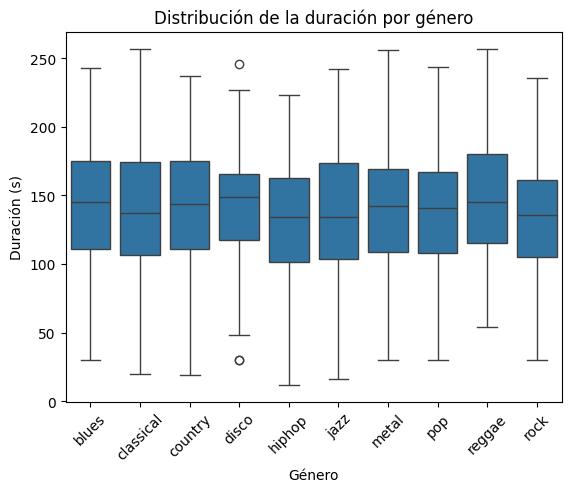

In [ ]:
sns.boxplot(data=df_cancion_sin_outliers,
            x="genero",
            y="duracion")

plt.xticks(rotation=45)
plt.title("Distribución de la duración por género")
plt.xlabel("Género")
plt.ylabel("Duración (s)")
plt.show()

El boxplot muestra que la duración de las canciones presentan una distribución similar entre los distintos géneros, con medianas y rangos intercuartilicos muy parecidos. Únicamente el género disco muestra algunos valores atípicos, correspondientes a canciones con duraciones inusualmente bajas o altas respecto al conjunto de canciones de ese género.

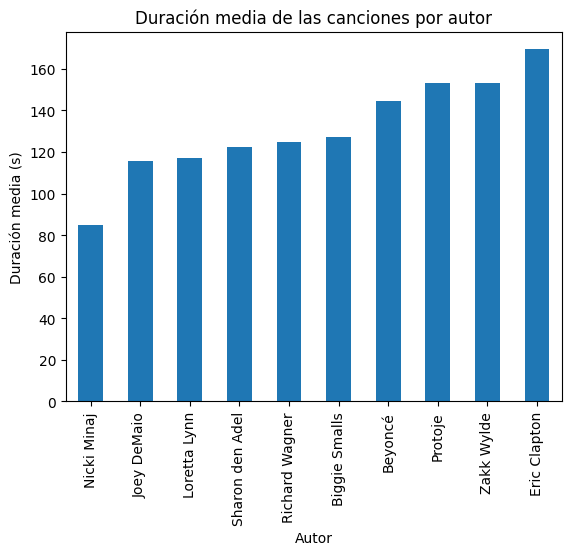

In [ ]:
#Como tenemos muchos autores, vamos a utilizar los 10 que tengan mas canciones
top_autores = df_cancion_sin_outliers['autor'].value_counts().sort_values(ascending=False).head(10).index
df_top_autores = df_cancion_sin_outliers[df_cancion_sin_outliers['autor'].isin(top_autores)]
df_top_autores.groupby('autor')["duracion"].mean().sort_values().plot(kind='bar')
plt.title('Duración media de las canciones por autor')
plt.xlabel("Autor")
plt.ylabel("Duración media (s)")
plt.show()

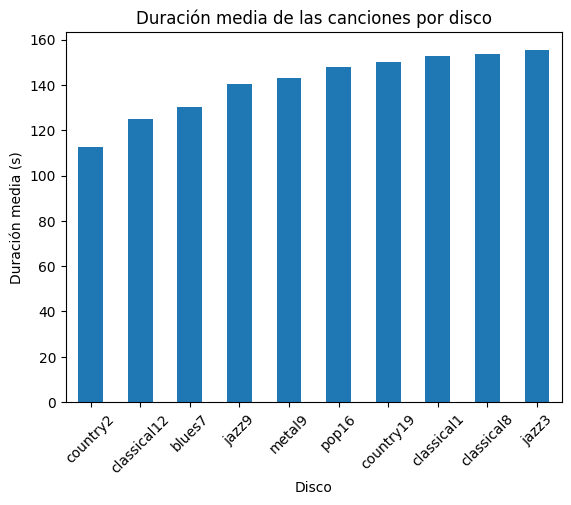

In [ ]:
#Como tenemos muchos discos, vamos a utilizar los 10 que tengan más canciones
top_discos = df_cancion_sin_outliers['disco'].value_counts().head(10).index

df_top_discos = df_cancion_sin_outliers[
    df_cancion_sin_outliers['disco'].isin(top_discos)
]

df_top_discos.groupby('disco')['duracion'].mean().sort_values().plot(kind='bar')

plt.title('Duración media de las canciones por disco')
plt.xlabel('Disco')
plt.ylabel('Duración media (s)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#ahora veamos duracion vs el numero de canciones por genero
df_group = df_cancion_sin_outliers.groupby('genero').agg({'duracion':'sum','cancion':'count'}).reset_index()
df_group

,genero,duracion,cancion
0,blues,13814.0,97
1,classical,13329.0,96
2,country,13547.0,97
3,disco,13952.0,98
4,hiphop,12646.0,95
5,jazz,13280.0,97
6,metal,13019.0,93
7,pop,13024.0,94
8,reggae,14038.0,96
9,rock,12453.0,94


<Axes: xlabel='cancion', ylabel='duracion'>

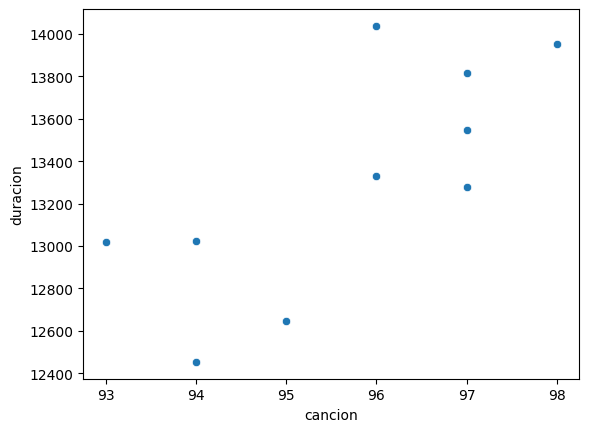

In [ ]:
sns.scatterplot(data=df_group, x='cancion', y='duracion')

El análisis muestra que la duración de las canciones presenta un comportamiento similar entre los distintos géneros y discos. Sin embargo, entre autores se observa una mayor variabilidad, lo que indica que la duración depende en mayor medida de las características de cada artista que del género musical o del disco al que pertenece la canción.